# Part 1: EDA, feature engineering, pipeline and baseline

Adult income project, Supervised Learning & Model Engineering (Ilana Sebag).

This is a simpler version of Lelia's notebook 01, same steps and same results, just written in a more basic way.

Dataset: Adult / Census Income from OpenML (version 2). Each row is one adult from the 1994 US census. The goal is to predict if the person earns more than 50K dollars a year (1) or not (0).

What we do here: look at the data, split it in train / validation / test, create some new features, put everything in one Pipeline and train a first model (the baseline).

## 1. Load the data

`sex` and `race` are sensitive attributes. We keep them because we need them later for the fairness audit.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay

RANDOM_STATE = 42

In [2]:
# download the dataset from openml (it is saved on the computer after the first time)
adult = fetch_openml(name="adult", version=2, as_frame=True)

X = adult.data.copy()
# the target is written as text ">50K" / "<=50K", we turn it into 1 / 0
y = (adult.target.astype(str) == ">50K").astype(int)
y.name = "income_over_50k"

df = X.copy()
df["income_over_50k"] = y

print("X shape:", X.shape)
df.head()

X shape: (48842, 14)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income_over_50k
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,0
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,0
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,1
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,1
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,0


## 2. First look at the data

In [3]:
summary = {
    "n_rows": df.shape[0],
    "n_columns": df.shape[1],
    "n_missing": df.isnull().sum().sum(),
    "n_duplicates": df.duplicated().sum(),
    "target_rate": df["income_over_50k"].mean(),
}
summary

{'n_rows': 48842,
 'n_columns': 15,
 'n_missing': np.int64(6465),
 'n_duplicates': np.int64(52),
 'target_rate': np.float64(0.23928176569346055)}

In [4]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype   
---  ------           --------------  -----   
 0   age              48842 non-null  int64   
 1   workclass        46043 non-null  category
 2   fnlwgt           48842 non-null  int64   
 3   education        48842 non-null  category
 4   education-num    48842 non-null  int64   
 5   marital-status   48842 non-null  category
 6   occupation       46033 non-null  category
 7   relationship     48842 non-null  category
 8   race             48842 non-null  category
 9   sex              48842 non-null  category
 10  capital-gain     48842 non-null  int64   
 11  capital-loss     48842 non-null  int64   
 12  hours-per-week   48842 non-null  int64   
 13  native-country   47985 non-null  category
 14  income_over_50k  48842 non-null  int64   
dtypes: category(8), int64(7)
memory usage: 3.0 MB


,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week,income_over_50k
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382,0.239282
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444,0.426649
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000,0.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000,0.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000,0.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000,0.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000,1.000000


In [5]:
# number of different values in each text column
X.select_dtypes(exclude="number").nunique()

workclass          8
education         16
marital-status     7
occupation        14
relationship       6
race               5
sex                2
native-country    41
dtype: int64

native-country has around 40 values and most of them are very rare, so later we group the rare ones together instead of making one column for each country. The numeric columns have very different scales (age is around 40, capital-gain goes up to 99,999) so we will need to scale them for the logistic regression.

There are 52 duplicated rows (0.1% of the data). We looked at them: they are mostly young people with very common profiles (for example 24 years old, private sector, bachelors, 35 hours a week), and 5 of them have exactly the same information but a different income, so they are clearly different people. In a census with only 14 columns it is normal that some people look the same, so we keep them.

## 3. The target

income_over_50k
0    37155
1    11687
Name: count, dtype: int64
Share of people earning more than 50K: 23.9 %


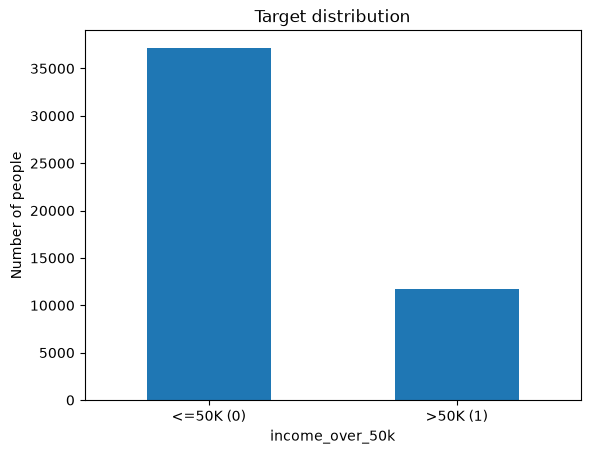

In [6]:
print(y.value_counts())
print("Share of people earning more than 50K:", round(y.mean() * 100, 1), "%")

y.value_counts().sort_index().plot(kind="bar")
plt.xticks([0, 1], ["<=50K (0)", ">50K (1)"], rotation=0)
plt.ylabel("Number of people")
plt.title("Target distribution")
plt.show()

Question: is the dataset balanced? Is accuracy enough to evaluate a model?

Answer: no, only about 24% of people earn more than 50K so the dataset is imbalanced. A model that always says "<=50K" would already get about 76% accuracy while being useless, so we will mostly look at precision, recall, F1, ROC-AUC and PR-AUC which look at how well we find the people earning more than 50K.

## 4. Missing values

In [7]:
missing = df.isnull().sum()
missing[missing > 0]

workclass         2799
occupation        2809
native-country     857
dtype: int64

In [8]:
# are workclass and occupation missing for the same people ?
pd.crosstab(df["workclass"].isnull(), df["occupation"].isnull())

occupation,False,True
workclass,,
False,46033,10
True,0,2799


In [9]:
# is the >50K rate different when the value is missing ?
for col in ["workclass", "occupation", "native-country"]:
    rate_missing = df[df[col].isnull()]["income_over_50k"].mean()
    rate_known = df[df[col].notnull()]["income_over_50k"].mean()
    print(col, "| >50K rate when missing:", round(rate_missing, 3), "| when known:", round(rate_known, 3))

workclass | >50K rate when missing: 0.095 | when known: 0.248
occupation | >50K rate when missing: 0.094 | when known: 0.248
native-country | >50K rate when missing: 0.257 | when known: 0.239


Question: how do we handle the missing values?

Answer: only 3 text columns have missing values (workclass, occupation, native-country). When workclass is missing, occupation is missing too, so these are probably people without a regular job (retired, students, unemployed). The >50K rate is much lower when they are missing (about 9.5% vs 24.8%), so the fact that it is missing is an information. Instead of guessing a value or deleting the rows we replace the missing values by a new category "Missing" that the model can use. For native-country it makes almost no difference.

## 5. Numeric columns

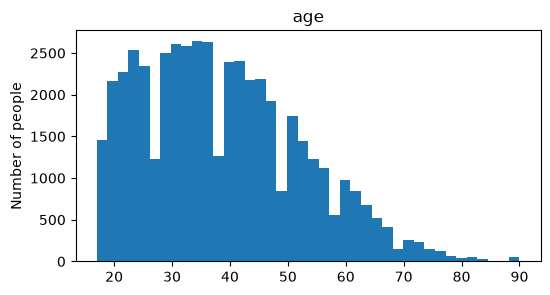

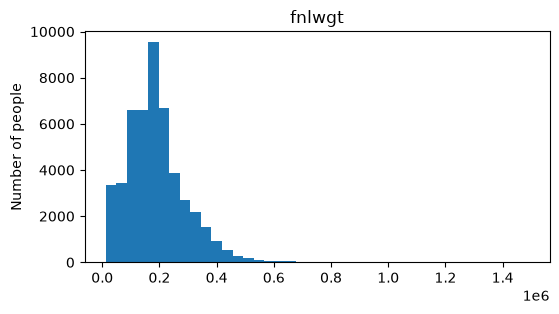

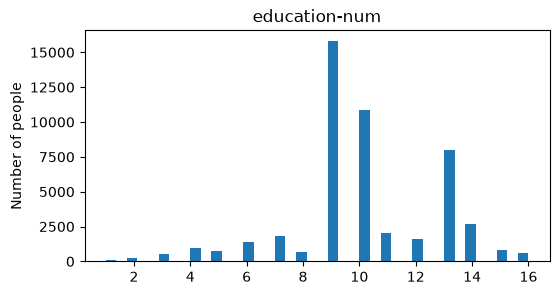

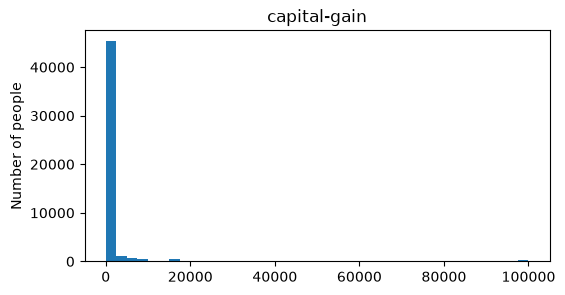

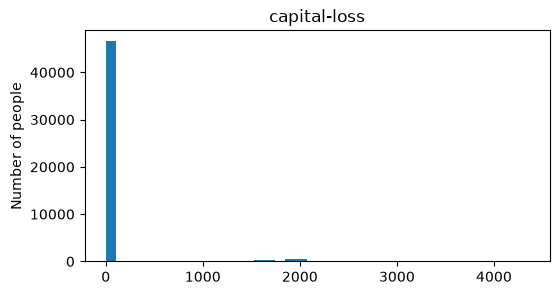

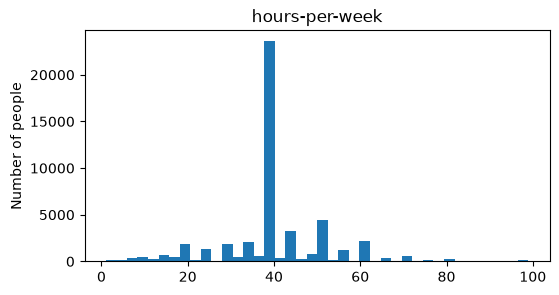

In [10]:
numeric_cols = ["age", "fnlwgt", "education-num", "capital-gain", "capital-loss", "hours-per-week"]

for col in numeric_cols:
    plt.figure(figsize=(6, 3))
    plt.hist(df[col], bins=40)
    plt.title(col)
    plt.ylabel("Number of people")
    plt.show()

In [11]:
for col in ["capital-gain", "capital-loss"]:
    print(col, ":", round((df[col] == 0).mean() * 100, 1), "% of people have 0, max =", df[col].max())

capital-gain : 91.7 % of people have 0, max = 99999
capital-loss : 95.3 % of people have 0, max = 4356


capital-gain and capital-loss are very skewed: more than 90% of people have exactly 0 and a few have huge values (99,999 is the max used in the census). For a linear model a value like 99,999 would crush everything, so we create a log version of capital-gain and a "has capital" flag (see part 8).

## 6. Which columns are linked to income?

In [12]:
def rate_by_group(df, feature):
    return df.groupby(feature, observed=True)["income_over_50k"].agg(n_people="count", rate_over_50k="mean").sort_values("rate_over_50k", ascending=False)

for feature in ["marital-status", "relationship", "education-num"]:
    print(rate_by_group(df, feature).round(3))
    print()

                       n_people  rate_over_50k
marital-status                                
Married-civ-spouse        22379          0.446
Married-AF-spouse            37          0.378
Divorced                   6633          0.101
Married-spouse-absent       628          0.092
Widowed                    1518          0.084
Separated                  1530          0.065
Never-married             16117          0.045

                n_people  rate_over_50k
relationship                           
Wife                2331          0.469
Husband            19716          0.449
Not-in-family      12583          0.101
Unmarried           5125          0.060
Other-relative      1506          0.035
Own-child           7581          0.015

               n_people  rate_over_50k
education-num                         
15                  834          0.740
16                  594          0.726
14                 2657          0.549
13                 8025          0.413
12                 16

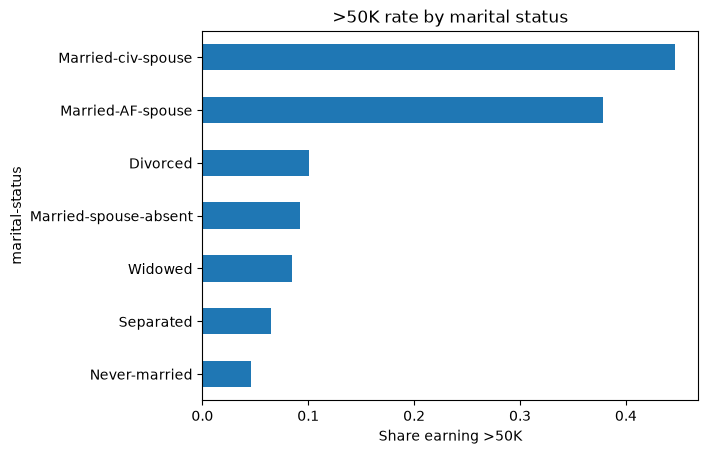

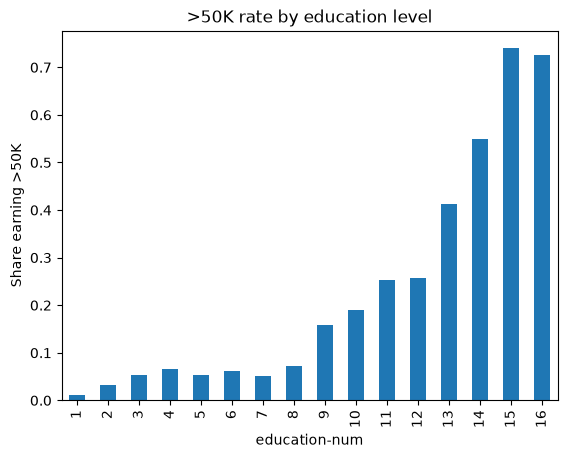

In [13]:
rate_by_group(df, "marital-status")["rate_over_50k"].sort_values().plot(kind="barh")
plt.title(">50K rate by marital status")
plt.xlabel("Share earning >50K")
plt.show()

rate_by_group(df, "education-num")["rate_over_50k"].sort_index().plot(kind="bar")
plt.title(">50K rate by education level")
plt.ylabel("Share earning >50K")
plt.show()

Marital status is very discriminative: married people (Married-civ-spouse) earn more than 50K much more often (around 45%) than never married people (around 5%). Part of it is just age (married people are older). The >50K rate also goes up almost every time education-num goes up. These are links, not causes: the table does not prove that getting married makes you earn more.

In [14]:
# sensitive attributes
for feature in ["sex", "race"]:
    print(rate_by_group(df, feature).round(3))
    print()

        n_people  rate_over_50k
sex                            
Male       32650          0.304
Female     16192          0.109

                    n_people  rate_over_50k
race                                       
Asian-Pac-Islander      1519          0.269
White                  41762          0.254
Other                    406          0.123
Black                   4685          0.121
Amer-Indian-Eskimo       470          0.117



Question: what does it mean for the fairness audit?

Answer: the rates are very different between groups, men earn more than 50K about 3 times more often than women in this data, and it also changes with race. A model trained on this data will learn these differences, so in the fairness audit we will check if the model treats the groups differently and if a correction reduces the gap.

## 7. Columns we remove

In [15]:
# each education label always has the same education-num ?
print(df.groupby("education", observed=True)["education-num"].nunique().max())
df.groupby("education", observed=True)["education-num"].first().sort_values()

1


education
Preschool        1
1st-4th          2
5th-6th          3
7th-8th          4
9th              5
10th             6
11th             7
12th             8
HS-grad          9
Some-college    10
Assoc-voc       11
Assoc-acdm      12
Bachelors       13
Masters         14
Prof-school     15
Doctorate       16
Name: education-num, dtype: int64

In [16]:
# >50K rate in 10 groups of fnlwgt
df.groupby(pd.qcut(df["fnlwgt"], q=10), observed=True)["income_over_50k"].mean().round(3)

fnlwgt
(12284.999, 65738.2]     0.216
(65738.2, 106072.2]      0.246
(106072.2, 130714.0]     0.254
(130714.0, 157932.0]     0.252
(157932.0, 178144.5]     0.252
(178144.5, 196308.0]     0.252
(196308.0, 220148.0]     0.235
(220148.0, 260254.0]     0.223
(260254.0, 328466.0]     0.223
(328466.0, 1490400.0]    0.240
Name: income_over_50k, dtype: float64

Question: which columns do we remove and why?

Answer: education is exactly the same information as education-num written as text (Bachelors is always 13), so we keep only education-num which also keeps the order of the levels. fnlwgt is a weight from the census that says how many people in the US this row represents, it is not something about the person. The >50K rate stays between about 22% and 25% in every group of fnlwgt with no trend, so we drop it.

## 8. Train / validation / test split

We use 3 sets:
train (60%) to fit the models, validation (20%) to compare models and choices, test (20%) that we keep locked and use only once at the very end.

If we compared models on the test set, we would adapt our choices to it and the final score would be too optimistic, that's why we need the validation set. We use stratify=y so the 3 sets keep the same 24% of >50K, and random_state=42 to always get the same split.

In [17]:
# first we cut the test set (20%)
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

# then we cut the rest in train and validation. 0.25 of the remaining 80% = 20% of the whole data
X_train, X_val, y_train, y_val = train_test_split(X_rest, y_rest, test_size=0.25, random_state=RANDOM_STATE, stratify=y_rest)

print("Train:", X_train.shape, ">50K rate:", round(y_train.mean(), 3))
print("Validation:", X_val.shape, ">50K rate:", round(y_val.mean(), 3))
print("Test:", X_test.shape, ">50K rate:", round(y_test.mean(), 3))

Train: (29304, 14) >50K rate: 0.239
Validation: (9769, 14) >50K rate: 0.239
Test: (9769, 14) >50K rate: 0.239


## 9. New features

We write one function that removes the 2 columns and creates 5 new ones. It does not learn anything from the data (fixed rules), so there is no risk of leakage. We will put it inside the pipeline so the same thing is done on train, validation, test and on any new person.

capital_net = capital-gain minus capital-loss, the result of the investments in one number.
has_capital = 1 if the person has any capital gain or loss, about 90% have 0 so having investments at all is already a sign of money.
log_capital_gain = log(1 + capital-gain), so 99,999 does not crush everything in a linear model.
is_married = 1 if Married-civ-spouse or Married-AF-spouse, the strongest group we saw in part 6.
works_overtime = 1 if hours-per-week is more than 40.

In [18]:
def add_new_features(X):
    X = X.copy()

    # remove the 2 columns we don't want
    X = X.drop(columns=["fnlwgt", "education"])

    # new features
    X["capital_net"] = X["capital-gain"] - X["capital-loss"]
    X["has_capital"] = ((X["capital-gain"] > 0) | (X["capital-loss"] > 0)).astype(int)
    X["log_capital_gain"] = np.log1p(X["capital-gain"])
    X["is_married"] = X["marital-status"].isin(["Married-civ-spouse", "Married-AF-spouse"]).astype(int)
    X["works_overtime"] = (X["hours-per-week"] > 40).astype(int)

    # the text columns are stored as "category", we turn them into normal text so the imputer can add "Missing"
    for col in X.select_dtypes("category").columns:
        X[col] = X[col].astype(object)

    return X

X_train_new = add_new_features(X_train)
print("Before:", X_train.shape, "After:", X_train_new.shape)
X_train_new[["capital_net", "has_capital", "log_capital_gain", "is_married", "works_overtime"]].head()

Before: (29304, 14) After: (29304, 17)


,capital_net,has_capital,log_capital_gain,is_married,works_overtime
30082,0,0,0.0,1,1
23803,0,0,0.0,1,0
13802,0,0,0.0,0,0
46557,0,0,0.0,0,0
38227,0,0,0.0,1,0


In [19]:
# do the new 0/1 features separate the classes ? (on the train set only)
train_new = X_train_new.copy()
train_new["income_over_50k"] = y_train.values

for feature in ["has_capital", "is_married", "works_overtime"]:
    print(rate_by_group(train_new, feature).round(3))
    print()

             n_people  rate_over_50k
has_capital                         
1                3791          0.575
0               25513          0.189

            n_people  rate_over_50k
is_married                         
1              13384          0.449
0              15920          0.063

                n_people  rate_over_50k
works_overtime                         
1                   8724          0.397
0                  20580          0.172



The 3 new 0/1 features separate the classes well: the >50K rate is several times higher when is_married = 1 or has_capital = 1, and higher for people working more than 40 hours. We will check later with SHAP if the model really uses them.

## 10. The pipeline

After the new features, the columns still need some preparation:
numeric columns: missing values replaced by the median, then StandardScaler (mean 0, std 1), the logistic regression needs it.
text columns: missing values replaced by "Missing", then one-hot encoding (one 0/1 column for each category).

Like in the homeworks, the preprocessing must be fitted on the train set only. The Pipeline does it for us: when we do pipe.fit(X_train, y_train) it learns the medians, means and categories on train, and pipe.predict(X_val) just reuses them.

The steps are: raw data, then add_new_features, then the preprocessing, then the model.

In [20]:
numeric_cols = ["age", "education-num", "capital-gain", "capital-loss", "hours-per-week", "capital_net", "has_capital", "log_capital_gain", "is_married", "works_overtime"]
categorical_cols = ["workclass", "marital-status", "occupation", "relationship", "race", "sex", "native-country"]

def build_pipeline(model):
    numeric_steps = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    # min_frequency=0.005: categories with less than 0.5% of the rows are grouped in one "infrequent" column
    # handle_unknown: if a new category shows up later, it goes in that group instead of crashing
    categorical_steps = Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.005, sparse_output=False)),
    ])
    preprocess = ColumnTransformer([
        ("num", numeric_steps, numeric_cols),
        ("cat", categorical_steps, categorical_cols),
    ])
    return Pipeline([
        ("new_features", FunctionTransformer(add_new_features)),
        ("preprocess", preprocess),
        ("model", model),
    ])

baseline_pipe = build_pipeline(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
baseline_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('new_features', ...), ('preprocess', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function add...t 0x12342c040>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneD

In [21]:
# quick check: we fit only the preparation steps (everything except the model) on train
X_train_ready = baseline_pipe[:-1].fit_transform(X_train, y_train)
print("Shape after preprocessing:", X_train_ready.shape)

Shape after preprocessing: (29304, 57)


We get 57 columns after the one-hot encoding, the very rare countries are grouped in one "infrequent" column.

## 11. Baseline

We train 2 models with the same pipeline:
a Dummy model that always predicts the most frequent class ("<=50K"), it learns nothing and is just the minimum level to beat,
a logistic regression, our real baseline, the first model that the next ones (random forest, LightGBM) will have to beat.

All scores are on the validation set, the test set stays locked. We use the same metrics as in the homeworks plus the PR-AUC (average_precision_score) which is more useful than ROC-AUC when the positive class is rare.

In [22]:
def get_metrics(y_true, y_pred, y_proba):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, y_proba),
        "pr_auc": average_precision_score(y_true, y_proba),
    }

In [23]:
dummy_pipe = build_pipeline(DummyClassifier(strategy="most_frequent"))
dummy_pipe.fit(X_train, y_train)
dummy_results = get_metrics(y_val, dummy_pipe.predict(X_val), dummy_pipe.predict_proba(X_val)[:, 1])

baseline_pipe.fit(X_train, y_train)
logreg_results = get_metrics(y_val, baseline_pipe.predict(X_val), baseline_pipe.predict_proba(X_val)[:, 1])

pd.DataFrame([dummy_results, logreg_results], index=["Dummy (most frequent)", "Logistic Regression"]).round(3)

,accuracy,precision,recall,f1,roc_auc,pr_auc
Dummy (most frequent),0.761,0.000,0.00,0.00,0.500,0.239
Logistic Regression,0.857,0.745,0.61,0.67,0.911,0.779


Question: what does the Dummy model tell us?

Answer: the Dummy model gets 76.1% accuracy without learning anything, but its precision, recall and F1 are 0 and its ROC-AUC is 0.5 (random). It confirms that accuracy is misleading here. The logistic regression is much better on all the metrics about the positive class, with a ROC-AUC of 0.911 on validation.

In [24]:
# train vs validation, is the baseline overfitting ?
train_results = get_metrics(y_train, baseline_pipe.predict(X_train), baseline_pipe.predict_proba(X_train)[:, 1])
pd.DataFrame({"train": train_results, "validation": logreg_results}).round(3)

,train,validation
accuracy,0.854,0.857
precision,0.740,0.745
recall,0.602,0.610
f1,0.664,0.670
roc_auc,0.910,0.911
pr_auc,0.774,0.779


Train and validation scores are very close so the logistic regression is not overfitting. It's a simple linear model so it's more limited by bias (it can't catch complex interactions), that's a reason to try tree models next.

[[6943  489]
 [ 912 1425]]


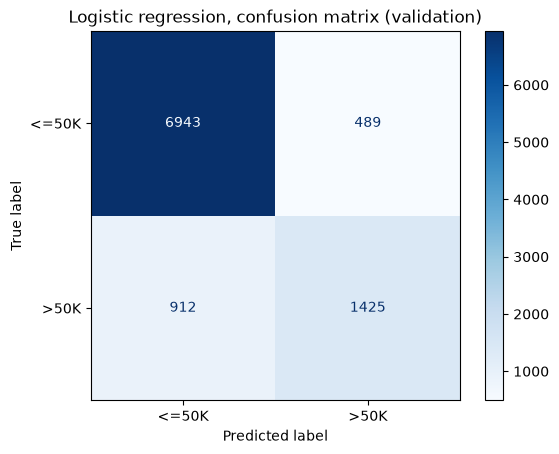

In [25]:
y_val_pred = baseline_pipe.predict(X_val)
y_val_proba = baseline_pipe.predict_proba(X_val)[:, 1]

cm = confusion_matrix(y_val, y_val_pred)
print(cm)
ConfusionMatrixDisplay(cm, display_labels=["<=50K", ">50K"]).plot(cmap="Blues")
plt.title("Logistic regression, confusion matrix (validation)")
plt.show()

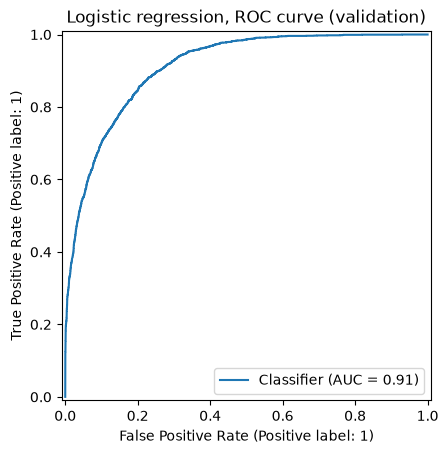

In [26]:
RocCurveDisplay.from_predictions(y_val, y_val_proba)
plt.title("Logistic regression, ROC curve (validation)")
plt.show()

Question: the model misses a lot of the people who really earn more than 50K. Why, and what can we do?

Answer: with the default threshold of 0.5 and only 24% of positives, the model is careful before saying ">50K". The recall is only 0.61, so 912 people earning more than 50K are missed (false negatives). It's the class imbalance problem. What we can try in the next notebook: class weights (class_weight="balanced") so the errors on the rare class cost more during training, resampling (undersampling or SMOTE) only on the train data inside the pipeline, or moving the decision threshold below 0.5 using the validation set.

## 12. Summary

EDA: about 24% of positives (imbalanced), missing values in 3 text columns (useful information so we keep a "Missing" category), very skewed capital columns, big income differences by marital status, education, sex and race.
Split: 60/20/20 train/validation/test with stratify, the test set is not touched.
Features: we removed fnlwgt and education and created 5 new features.
Pipeline: new features + imputation + scaling + one-hot + model, fitted on train only.
Baseline: the logistic regression is much better than the Dummy model, no overfitting but a low recall.

Next: class imbalance and the 3 models (notebook 02), then Optuna tuning with cross-validation and MLflow, then SHAP, calibration and the fairness audit on sex.